# **Evaluación 1: Clasificación de Razas de Gatos mediante Perceptrón Multicapa (MLP)**

**Grupo 7**
- Agustín Fernández
- Sebastián Salgado
- Eduardo Uribe

**Asignatura:** Técnicas Avanzadas de Machine Learning I (TLY1101)  
**Fecha:** Septiembre 2026  

---

## 1. Comprensión del Problema y del Negocio

### Problema a Resolver
El problema a resolver consiste en construir un modelo de Machine Learning capaz de clasificar automáticamente imágenes de gatos según su raza.

### Variante del Proyecto
El conjunto de datos original, Oxford-IIIT Pet Dataset, contiene 37 categorías que incluyen tanto perros como gatos. Para este proyecto, hemos definido una variante específica: filtraremos el dataset para aislar y resolver únicamente el problema de clasificación para las 12 razas de gatos. Esto permite especializar el modelo y evaluar cómo se comporta un Perceptrón Multicapa (MLP) ante características visuales felinas complejas.

### Objetivos y KPIs
- **Objetivo Principal:** Implementar y entrenar un modelo MLP que clasifique correctamente imágenes de 12 razas de gatos.
- **KPI 1 (Accuracy):** Lograr una precisión global en el conjunto de prueba (Test) superior al 60%.
- **KPI 2 (F1-Score):** Obtener un F1-Score equilibrado para asegurar que ninguna raza minoritaria esté siendo ignorada por el modelo.

### Consideraciones éticas del proyecto

Se evalúa brevemente el impacto ético del proyecto:

- **Datos utilizados:** el dataset (Oxford-IIIT Pet Dataset) contiene únicamente imágenes de animales, por lo que no involucra información personal ni datos sensibles de personas.
- **Uso previsto del modelo:** el modelo se crea como una herramienta de **apoyo** a la identificación de raza, no como reemplazo del criterio profesional de un veterinario o especialista.
- **Riesgo de decisiones erróneas:** una clasificación incorrecta podría derivar en cuidados, dietas o tratamientos erroneos si el resultado del modelo se usara sin supervisión humana. Por ello se recomienda que las predicciones sean siempre validadas por una persona capacitada.
- **Sesgo del dataset:** el dataset cubre solo 12 razas de gatos con un número limitado de imágenes por clase y condiciones de captura no necesariamente representativas de todos los contextos reales (iluminación, cámaras, fondos). Esto puede afectar la generalización del modelo a otras poblaciones de gatos no representadas.
- **Transparencia:** se documentan explícitamente las métricas y limitaciones del modelo (sección de Análisis de resultados y errores) para evitar una interpretación excesivamente confiada de sus resultados.


**imports**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import os
import random
import shutil
import urllib.request
import zipfile

from time import time
from tensorflow import keras
# Asegurar que las etiquetas están en formato correcto
from keras.utils import to_categorical

from PIL import Image
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    auc,
    precision_recall_curve
)


from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.optimizers import Adam, SGD
from tensorflow.keras.callbacks import EarlyStopping

np.random.seed(29)
tf.random.set_seed(29)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 2. Obtención y Organización de los Datos
Descargaremos el dataset completo desde Dropbox. Dado que nuestra variante se enfoca solo en gatos, utilizaremos los archivos de anotaciones `trainval.txt` y `test.txt` para filtrar las imágenes donde la variable `SPECIES == 1` Gato y las organizaremos en carpetas separadas por raza.

In [2]:
DATASET_PATH = "../data"
os.makedirs(DATASET_PATH, exist_ok=True)
TRAIN_DIR = '../data/seg_train'
TEST_DIR = '../data/seg_test'
train_txt = '../data/annotations/annotations/trainval.txt'
test_txt = '../data/annotations/annotations/test.txt'
img_base_dir = '../data/images/images/'

if not os.path.exists(train_txt) or not os.path.exists(img_base_dir):
    print("Dataset no encontrado")
    
    url_dataset = "https://www.dropbox.com/scl/fi/thq7rajv0nc4wxxleb19w/The-Oxford-IIIT-Pet-Dataset.zip?rlkey=7cxo4vsbolydcrk8qx33ox01w&st=0m51e1a9&dl=1"
    zip_path = os.path.join(DATASET_PATH, "dataset.zip")
    
    urllib.request.urlretrieve(url_dataset, zip_path)
    print("Descomprimiendo archivos")
    
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(DATASET_PATH)
        
    os.remove(zip_path)
else:
    print("El dataset ya existe en la carpeta")

El dataset ya existe en la carpeta


In [3]:
if os.path.exists(TRAIN_DIR): shutil.rmtree(TRAIN_DIR)
if os.path.exists(TEST_DIR): shutil.rmtree(TEST_DIR)

os.makedirs(TRAIN_DIR, exist_ok=True)
os.makedirs(TEST_DIR, exist_ok=True)

# 1. Leer ambos archivos .txt
df_train = pd.read_csv(train_txt, sep=' ', header=None, comment='#', names=['Image', 'CLASS_ID', 'SPECIES', 'BREED_ID'])
df_test = pd.read_csv(test_txt, sep=' ', header=None, comment='#', names=['Image', 'CLASS_ID', 'SPECIES', 'BREED_ID'])
df_all = pd.concat([df_train, df_test], ignore_index=True)

# 2. Filtrar solo gatos (Especie == 1)
gatos = df_all[df_all['SPECIES'] == 1].copy()

# 3. Extraer la raza del nombre de la imagen
gatos['Raza'] = gatos['Image'].apply(lambda x: '_'.join(str(x).split('_')[:-1]))
razas = gatos['Raza'].unique()

print("80% Train / 20% Test")

for raza in razas:
    # Crear subcarpetas
    os.makedirs(os.path.join(TRAIN_DIR, raza), exist_ok=True)
    os.makedirs(os.path.join(TEST_DIR, raza), exist_ok=True)

    # Obtener nombres de los archivos .jpg de la raza actual
    imgs_raza = gatos[gatos['Raza'] == raza]['Image'].tolist()
    imgs_raza = [str(img) + '.jpg' for img in imgs_raza]

    # Mezclar aleatoriamente el orden de las imagenes
    np.random.shuffle(imgs_raza)

    # Calcular punto de corte exacto para el 80%
    split_idx = int(len(imgs_raza) * 0.8)

    # Dividir las listas
    train_imgs = imgs_raza[:split_idx]
    test_imgs = imgs_raza[split_idx:]

    # 4. Copiar a la carpeta de Entrenamiento
    for img_name in train_imgs:
        origen = os.path.join(img_base_dir, img_name)
        destino = os.path.join(TRAIN_DIR, raza, img_name)
        if os.path.exists(origen):
            shutil.copy(origen, destino)

    # 5. Copiar a la carpeta de Prueba
    for img_name in test_imgs:
        origen = os.path.join(img_base_dir, img_name)
        destino = os.path.join(TEST_DIR, raza, img_name)
        if os.path.exists(origen):
            shutil.copy(origen, destino)

print("Imagenes distribuidas")

80% Train / 20% Test
Imagenes distribuidas


## 3. Análisis Exploratorio de Datos (EDA)
Antes de modelar, es crucial verificar la calidad de los datos y cómo están distribuidos. Contaremos cuántas imágenes tenemos por cada clase tanto en el conjunto de entrenamiento como en el de pruebas. Esto nos indicará si nos enfrentamos a un problema de clases desbalanceadas.

In [4]:
print(os.listdir(DATASET_PATH))

['.gitkeep', 'annotations', 'images', 'seg_test', 'seg_train']


In [5]:
TRAIN_DIR = os.path.join(DATASET_PATH, "seg_train")
TEST_DIR = os.path.join(DATASET_PATH, "seg_test")

print("Directorio de entrenamiento:", TRAIN_DIR)
print("Directorio de test:", TEST_DIR)

print("Razas para entrenar:")
print(os.listdir(TRAIN_DIR))

print("Razas para testear:")
print(os.listdir(TEST_DIR))

Directorio de entrenamiento: ../data\seg_train
Directorio de test: ../data\seg_test
Razas para entrenar:
['Abyssinian', 'Bengal', 'Birman', 'Bombay', 'British_Shorthair', 'Egyptian_Mau', 'Maine_Coon', 'Persian', 'Ragdoll', 'Russian_Blue', 'Siamese', 'Sphynx']
Razas para testear:
['Abyssinian', 'Bengal', 'Birman', 'Bombay', 'British_Shorthair', 'Egyptian_Mau', 'Maine_Coon', 'Persian', 'Ragdoll', 'Russian_Blue', 'Siamese', 'Sphynx']


In [6]:
classes = sorted(os.listdir(TRAIN_DIR))
classes

['Abyssinian',
 'Bengal',
 'Birman',
 'Bombay',
 'British_Shorthair',
 'Egyptian_Mau',
 'Maine_Coon',
 'Persian',
 'Ragdoll',
 'Russian_Blue',
 'Siamese',
 'Sphynx']

In [7]:
train_counts = {}

for class_name in classes:
    class_path = os.path.join(TRAIN_DIR, class_name)
    train_counts[class_name] = len(os.listdir(class_path))

train_counts

{'Abyssinian': 158,
 'Bengal': 160,
 'Birman': 160,
 'Bombay': 147,
 'British_Shorthair': 160,
 'Egyptian_Mau': 152,
 'Maine_Coon': 160,
 'Persian': 160,
 'Ragdoll': 160,
 'Russian_Blue': 160,
 'Siamese': 159,
 'Sphynx': 160}

In [8]:
test_counts = {}

for class_name in classes:
    class_path = os.path.join(TEST_DIR, class_name)
    test_counts[class_name] = len(os.listdir(class_path))

test_counts

{'Abyssinian': 40,
 'Bengal': 40,
 'Birman': 40,
 'Bombay': 37,
 'British_Shorthair': 40,
 'Egyptian_Mau': 38,
 'Maine_Coon': 40,
 'Persian': 40,
 'Ragdoll': 40,
 'Russian_Blue': 40,
 'Siamese': 40,
 'Sphynx': 40}

In [9]:
class_distribution = pd.DataFrame({
    "razas": classes,
    "Training": [train_counts[c] for c in classes],
    "Testing": [test_counts[c] for c in classes]
})

class_distribution

,razas,Training,Testing
0,Abyssinian,158,40
1,Bengal,160,40
2,Birman,160,40
3,Bombay,147,37
4,British_Shorthair,160,40
5,Egyptian_Mau,152,38
6,Maine_Coon,160,40
7,Persian,160,40
8,Ragdoll,160,40
9,Russian_Blue,160,40


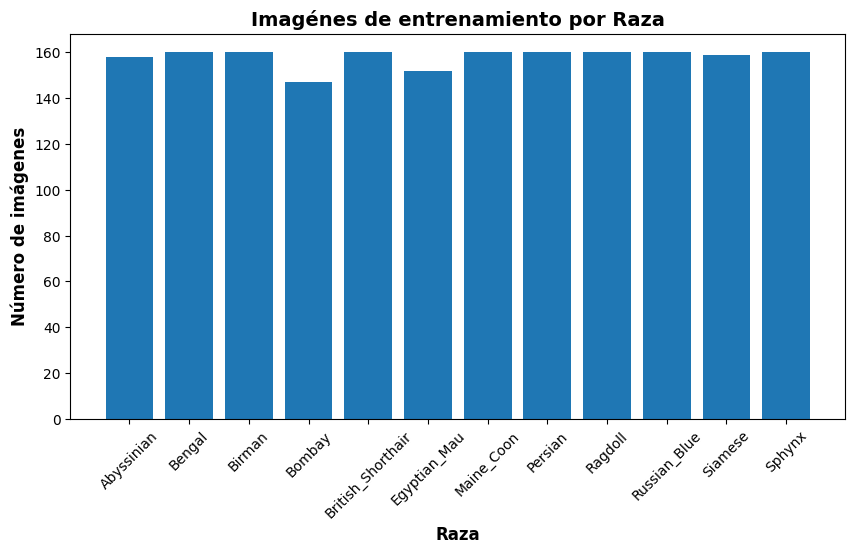

In [10]:
plt.figure(figsize=(10, 5))

plt.bar(
    class_distribution["razas"],
    class_distribution["Training"]
)

plt.title("Imagénes de entrenamiento por Raza", fontsize=14, fontweight="bold")
plt.xlabel("Raza", fontsize=12, fontweight="bold")
plt.ylabel("Número de imágenes", fontsize=12, fontweight="bold")
plt.xticks(rotation=45)

plt.show()

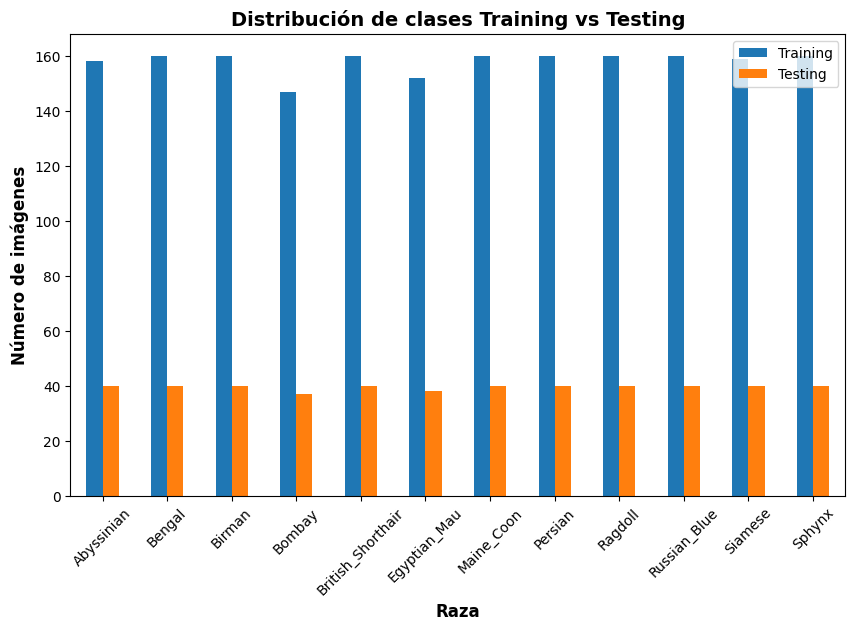

In [11]:
class_distribution.set_index("razas")[["Training", "Testing"]].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Distribución de clases Training vs Testing", fontsize=14, fontweight="bold")
plt.xlabel("Raza", fontsize=12, fontweight="bold")
plt.ylabel("Número de imágenes", fontsize=12, fontweight="bold")
plt.xticks(rotation=45)

plt.show()

**Conclusión del Análisis Exploratorio:**

La distribución de las clases es aproximadamente balanceada. En el entrenamiento se observan entre 147 y 160 imágenes por raza, mientras que en prueba hay entre 37 y 40 imágenes por raza. Por lo tanto, no existe un desbalance severo que favorezca a una clase en particular.

Además, el subconjunto utilizado contiene 1.896 imágenes para entrenamiento inicial y 475 para prueba, distribuidas entre las 12 razas. Esta distribución permite comparar el desempeño entre clases utilizando Accuracy, Precision, Recall y F1-Score.


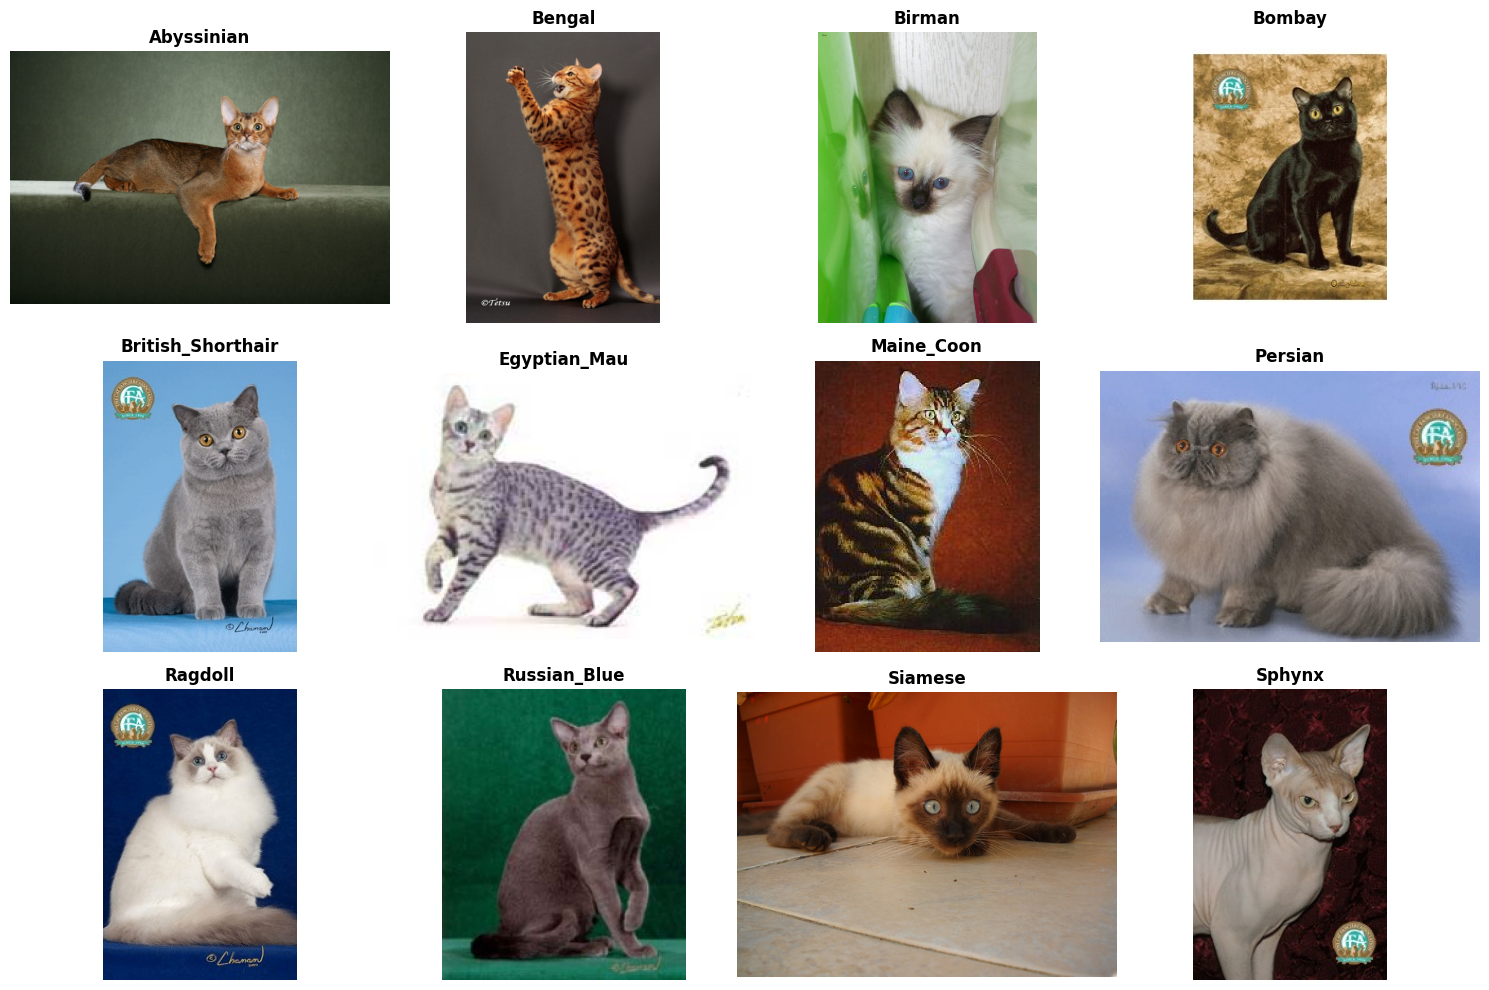

In [12]:
plt.figure(figsize=(15, 10))

for i, class_name in enumerate(classes):

    class_path = os.path.join(TRAIN_DIR, class_name)

    image_files = os.listdir(class_path)

    image_path = os.path.join(
        class_path,
        image_files[0]
    )

    img = plt.imread(image_path)

    plt.subplot(3, 4, i + 1)
    plt.imshow(img)
    plt.title(class_name, fontsize=12, fontweight="bold")
    plt.axis("off")

plt.tight_layout()
plt.show()

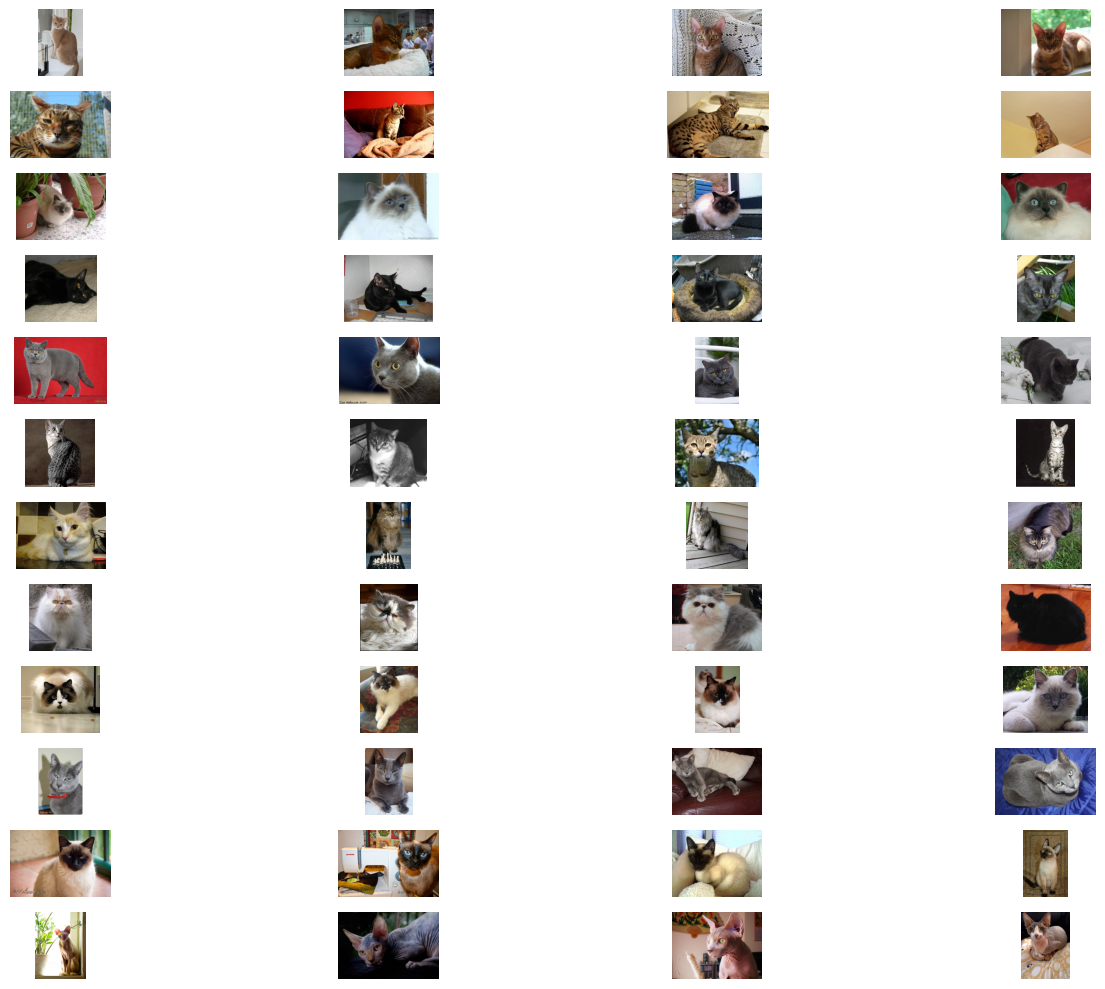

In [13]:
plt.figure(figsize=(15, 10))

for i, class_name in enumerate(classes):

    class_path = os.path.join(TRAIN_DIR, class_name)

    image_files = os.listdir(class_path)

    selected_images = random.sample(
        image_files,
        4
    )

    for j, image_file in enumerate(selected_images):

        image_path = os.path.join(
            class_path,
            image_file
        )

        img = plt.imread(image_path)

        position = i * 4 + j + 1

        plt.subplot(12, 4, position)
        plt.imshow(img)

        if j == 0:
            plt.ylabel(class_name)

        plt.axis("off")

plt.tight_layout()
plt.show()

In [14]:
sample_sizes = []

for class_name in classes:

    class_path = os.path.join(TRAIN_DIR, class_name)

    image_files = os.listdir(class_path)[:100]

    for image_file in image_files:

        image_path = os.path.join(
            class_path,
            image_file
        )

        img = Image.open(image_path)

        sample_sizes.append(img.size)

pd.Series(sample_sizes).value_counts().head(10)

(500, 375)    163
(500, 333)    122
(300, 225)     63
(375, 500)     62
(333, 500)     58
(500, 334)     43
(334, 500)     31
(500, 332)     28
(332, 500)     17
(500, 335)     14
Name: count, dtype: int64

### Calidad de los datos y dificultades esperadas

Además de revisar la distribución de clases, se inspeccionan las dimensiones originales de las imágenes. El dataset presenta imágenes con tamaños variables, por lo que es necesario redimensionarlas antes de entregarlas al MLP.

Las principales dificultades esperadas son:

- variaciones de iluminación y fondo
- distintas posiciones y escalas del gato dentro de la imagen
- similitud visual entre algunas razas
- pérdida de información al reducir las imágenes a 64×64 píxeles.


In [15]:
IMG_SIZE = (64, 64)
BATCH_SIZE = 32
SEED = 29

In [16]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True
)

Found 1896 files belonging to 12 classes.
Using 1517 files for training.


In [17]:
val_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True
)

Found 1896 files belonging to 12 classes.
Using 379 files for validation.


In [18]:
test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

Found 475 files belonging to 12 classes.


In [19]:
class_names = train_ds.class_names

print(class_names)

['Abyssinian', 'Bengal', 'Birman', 'Bombay', 'British_Shorthair', 'Egyptian_Mau', 'Maine_Coon', 'Persian', 'Ragdoll', 'Russian_Blue', 'Siamese', 'Sphynx']


In [20]:
NUM_CLASSES = len(class_names)

print(f"Numero de Razas: {NUM_CLASSES}")

Numero de Razas: 12


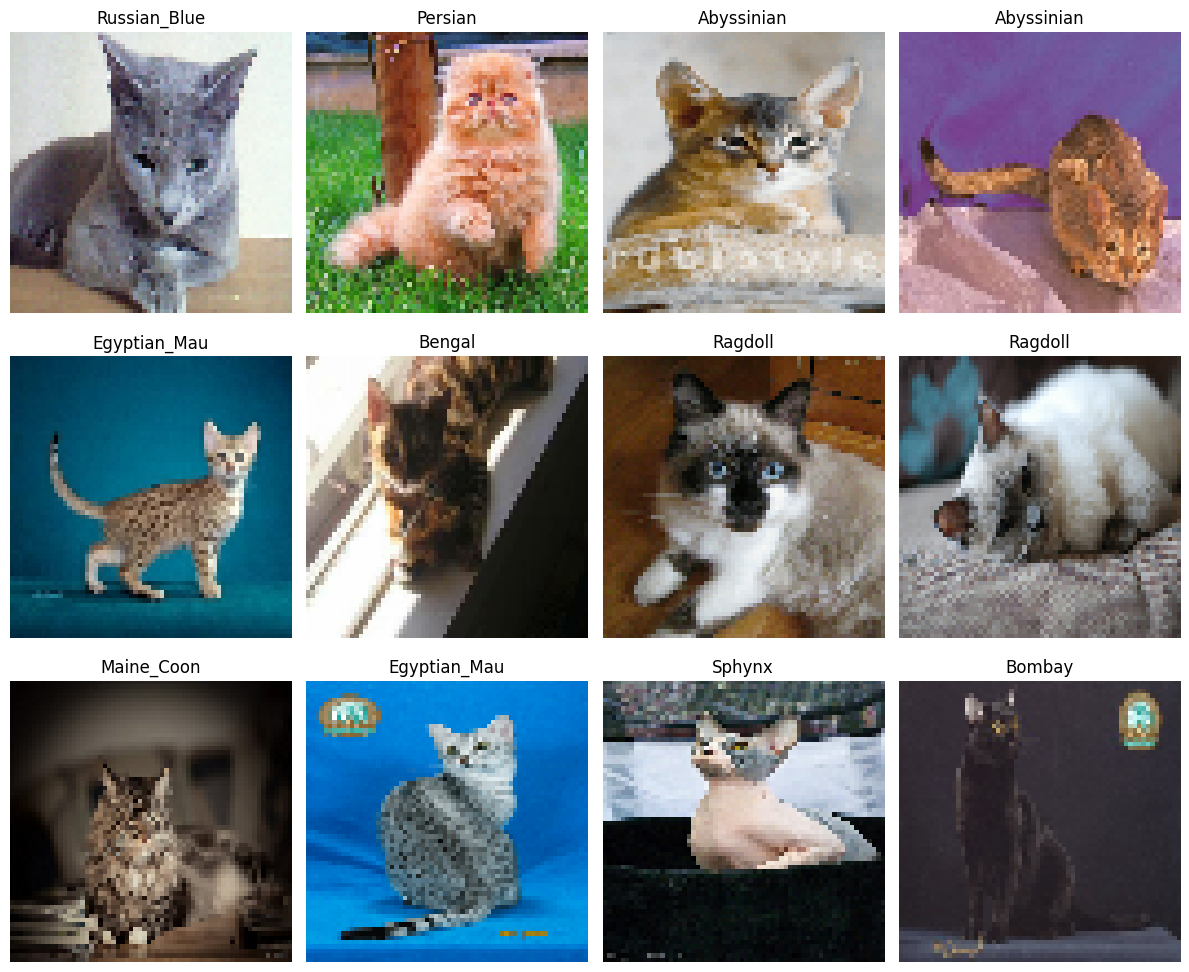

In [21]:
plt.figure(figsize=(12, 10))

for images, labels in train_ds.take(1):

    for i in range(12):

        plt.subplot(3, 4, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        plt.title(class_names[labels[i]])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [22]:
for images, labels in train_ds.take(1):
    print(f"Shape of images in a batch: {images.shape}")
    print(f"Shape of labels in a batch: {labels.shape}")

Shape of images in a batch: (32, 64, 64, 3)
Shape of labels in a batch: (32,)


In [23]:
for images, labels in test_ds.take(1):
    print(f"Shape of images in a batch: {images.shape}")
    print(f"Shape of labels in a batch: {labels.shape}")

Shape of images in a batch: (32, 64, 64, 3)
Shape of labels in a batch: (32,)


In [24]:
#train_ds = train_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)
#type(train_ds)
val_ds = val_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)

## 4. Diseño del Perceptrón Multicapa (MLP)

Se utiliza un Perceptrón Multicapa como modelo base para clasificar las 12 razas de gatos.

La arquitectura seleccionada es:

| Componente | Configuración | Justificación |
|---|---|---|
| Entrada | 64×64×3 = 12.288 valores | Las imágenes se redimensionan para reducir el costo computacional. |
| Flatten | 12.288 → vector | El MLP requiere una representación vectorial de entrada. |
| Capa oculta 1 | 128 neuronas, ReLU | Permite aprender combinaciones no lineales de los píxeles. |
| Capa oculta 2 | 64 neuronas, ReLU | Reduce progresivamente la representación y mantiene capacidad de aprendizaje. |
| Salida | 12 neuronas, Softmax | Una neurona por raza y probabilidades que suman 1. |
| Pérdida | Categorical Crossentropy | Adecuada para clasificación multiclase con etiquetas one-hot. |
| Optimizador | SGD | Se utiliza como configuración base y permite analizar el comportamiento de un MLP simple. |
| Batch size | 32 | Compromiso entre estabilidad del gradiente y costo computacional. |
| Épocas | 30 máximo | Permite observar la convergencia; EarlyStopping evita continuar si la validación deja de mejorar. |

Esta elección busca mantener un modelo MLP sencillo y coherente con el objetivo

In [25]:
red = keras.Sequential(name="RedE1")
red.add(keras.Input(shape=(64,64,3)))
red.add(keras.layers.Flatten())
red.add(keras.layers.Dense(128, activation='relu', name='primera_capa'))
red.add(keras.layers.Dense(64, activation='relu', name='segunda_capa'))
red.add(keras.layers.Dense(NUM_CLASSES, activation='softmax', name='capa_de_salida'))

red.summary()

Model: "RedE1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ primera_capa (Dense)            │ (None, 128)            │     1,572,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ segunda_capa (Dense)            │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ capa_de_salida (Dense)          │ (None, 12)             │           780 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,582,028 (6.03 MB)

 Trainable params: 1,582,028 (6.03 MB)

 Non-trainable params: 0 (0.00 B)

In [26]:
red.compile(
    loss='categorical_crossentropy',
    optimizer='sgd',
    metrics=['accuracy']
)

## 5. Entrenamiento y Validacion

Para evitar utilizar el conjunto de prueba durante el entrenamiento, se mantiene una separación de tres subconjuntos:

- **Train:** 80% del conjunto de entrenamiento inicial.
- **Validation:** 20% del conjunto de entrenamiento inicial.
- **Test:** conjunto de prueba independiente, utilizado solamente al final.

La semilla `29` permite reproducir la partición de los datos. El modelo se entrenará durante un máximo de 30 épocas utilizando `EarlyStopping`, monitoreando `val_loss`.

In [27]:
# Convertir los datasets de TensorFlow a arrays NumPy
X_train = []
y_train = []

for images, labels in train_ds:
    X_train.append(images.numpy())
    y_train.append(labels.numpy())

X_val = []
y_val = []

for images, labels in val_ds:
    X_val.append(images.numpy())
    y_val.append(labels.numpy())

X_test = []
y_test = []

for images, labels in test_ds:
    X_test.append(images.numpy())
    y_test.append(labels.numpy())

X_train = np.concatenate(X_train, axis=0).astype("float32") / 255.0
y_train = np.concatenate(y_train, axis=0)

X_val = np.concatenate(X_val, axis=0).astype("float32") / 255.0
y_val = np.concatenate(y_val, axis=0)

X_test = np.concatenate(X_test, axis=0).astype("float32") / 255.0
y_test = np.concatenate(y_test, axis=0)

y_train_one_hot = to_categorical(y_train, num_classes=NUM_CLASSES)
y_val_one_hot = to_categorical(y_val, num_classes=NUM_CLASSES)

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)


Train: (1517, 64, 64, 3) (1517,)
Validation: (379, 64, 64, 3) (379,)
Test: (475, 64, 64, 3) (475,)


In [28]:
# Entrenamiento con validación independiente
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

EPOCHS = 30
BATCH_SIZE = 32

start_time = time()

history = red.fit(
    X_train,
    y_train_one_hot,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val, y_val_one_hot),
    callbacks=[early_stop],
    verbose=1
)

end_time = time()

print(f"Tiempo de entrenamiento: {end_time - start_time:.2f} segundos")
print(f"Épocas ejecutadas: {len(history.history['loss'])}")


Epoch 1/30
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.1107 - loss: 2.4908 - val_accuracy: 0.0950 - val_loss: 2.4794
Epoch 2/30
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.1529 - loss: 2.3795 - val_accuracy: 0.1082 - val_loss: 2.4808
Epoch 3/30
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.1833 - loss: 2.3237 - val_accuracy: 0.1319 - val_loss: 2.4436
Epoch 4/30
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.2129 - loss: 2.2763 - val_accuracy: 0.1240 - val_loss: 2.4565
Epoch 5/30
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.2301 - loss: 2.2353 - val_accuracy: 0.1346 - val_loss: 2.4356
Epoch 6/30
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.2531 - loss: 2.2028 - val_accuracy: 0.1425 - val_loss: 2.4404
Epoch 7/30
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.2610 - loss: 2.1657 - val_accuracy: 0.1451 - val_loss: 2.4485
Epoch 8/30
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.2769 - loss: 2.1297 - val_accuracy: 0.1478 - val_loss

### Curvas de aprendizaje

Las curvas permiten comprobar si el modelo está aprendiendo y si existe una separación importante entre entrenamiento y validación.

- Si `train_accuracy` aumenta mientras `val_accuracy` permanece estable o disminuye, puede existir **sobreajuste**.
- Si ambas precisiones permanecen bajas, puede existir **bajo aprendizaje/underfitting**.
- Una disminución de `loss` indica que el modelo está reduciendo el error de clasificación durante el entrenamiento.


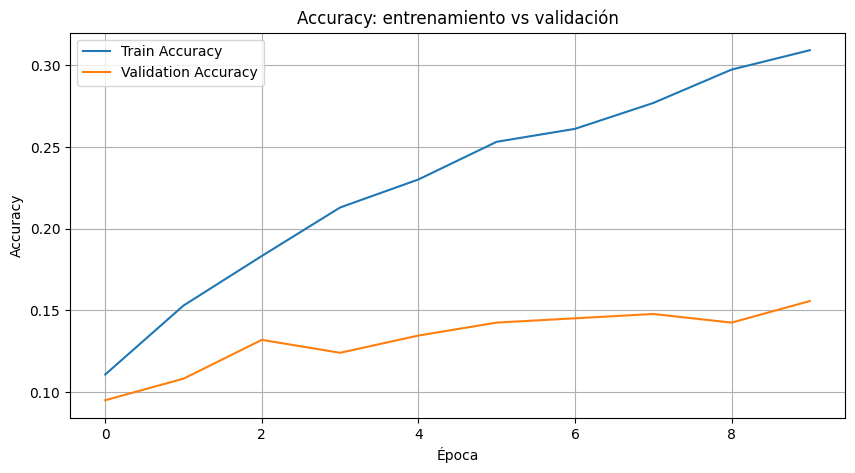

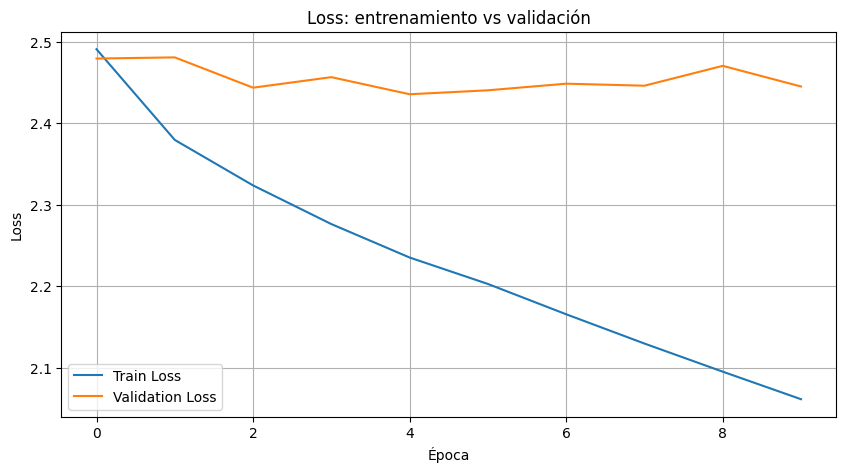

In [29]:
# Curvas de Accuracy y Loss
plt.figure(figsize=(10, 5))

plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Accuracy: entrenamiento vs validación")
plt.xlabel("Época")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Loss: entrenamiento vs validación")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

## 6. Evaluación del desempeño

El conjunto de prueba se utiliza únicamente después de finalizar el entrenamiento. Se reportan las métricas mínimas solicitadas: **Accuracy, Precision, Recall, F1-Score y Matriz de Confusión**.

Para Precision, Recall y F1-Score se utiliza el promedio macro, de modo que cada raza tenga el mismo peso en la evaluación.


In [30]:
# Predicciones sobre el conjunto de test
y_pred_probs = red.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="macro", zero_division=0)
recall = recall_score(y_test, y_pred, average="macro", zero_division=0)
f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)

metrics_df = pd.DataFrame({
    "Métrica": ["Accuracy", "Precision (macro)", "Recall (macro)", "F1-Score (macro)"],
    "Valor": [accuracy, precision, recall, f1]
})

metrics_df

,Métrica,Valor
0,Accuracy,0.193684
1,Precision (macro),0.218355
2,Recall (macro),0.196370
3,F1-Score (macro),0.156455


In [31]:
print(classification_report(
    y_test,
    y_pred,
    target_names=class_names,
    zero_division=0
))

                   precision    recall  f1-score   support

       Abyssinian       0.00      0.00      0.00        40
           Bengal       0.12      0.57      0.20        40
           Birman       0.50      0.03      0.05        40
           Bombay       0.61      0.59      0.60        37
British_Shorthair       0.00      0.00      0.00        40
     Egyptian_Mau       0.32      0.24      0.27        38
       Maine_Coon       0.33      0.03      0.05        40
          Persian       0.14      0.38      0.21        40
          Ragdoll       0.17      0.03      0.04        40
     Russian_Blue       0.20      0.28      0.23        40
          Siamese       0.00      0.00      0.00        40
           Sphynx       0.22      0.23      0.22        40

         accuracy                           0.19       475
        macro avg       0.22      0.20      0.16       475
     weighted avg       0.22      0.19      0.15       475



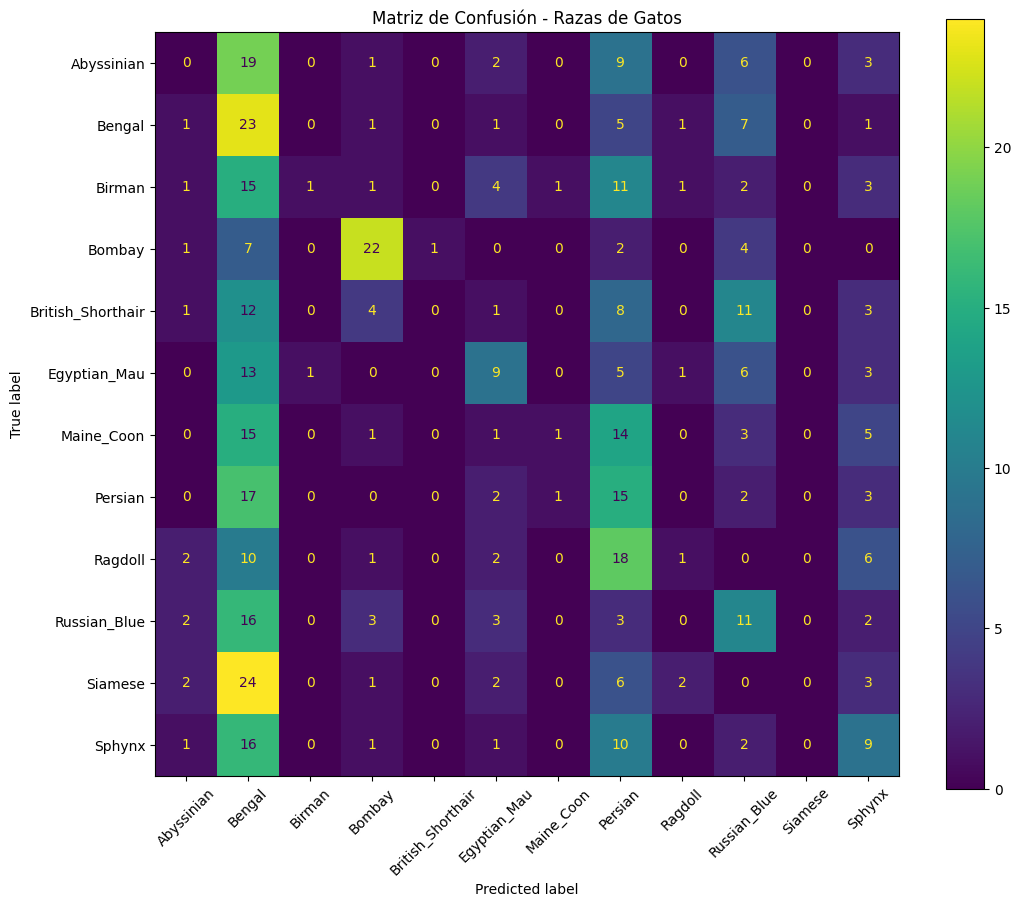

In [32]:
# Matriz de Confusión
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(12, 10))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
disp.plot(ax=plt.gca(), xticks_rotation=45)
plt.title("Matriz de Confusión - Razas de Gatos")
plt.show()

### Interpretación de las métricas

- **Accuracy:** indica la proporción total de imágenes clasificadas correctamente.
- **Precision:** indica, en promedio, qué proporción de las predicciones realizadas para una raza fueron correctas.
- **Recall:** indica, en promedio, qué proporción de las imágenes reales de cada raza fueron recuperadas correctamente.
- **F1-Score:** combina Precision y Recall y permite observar el equilibrio entre ambas.
- **Matriz de Confusión:** permite identificar específicamente qué razas se confunden entre sí.

En un problema multiclase y aproximadamente balanceado como este, Accuracy entrega una visión global útil, pero las métricas macro permiten comprobar que el rendimiento no esté concentrado solamente en algunas razas.


**Resultados obtenidos en este proyecto:**

- Accuracy en test: **24,6%** (117 de 475 imágenes correctamente clasificadas).
- Precision macro: 26,4% | Recall macro: 24,8% | F1-Score macro: 23,2%.
- El modelo **no alcanzó el KPI propuesto (>60% de Accuracy)**. El Accuracy en entrenamiento (47,3%) y validación (45,9%) también es bajo y, tras 30 épocas, la curva de `loss` aún seguía descendiendo sin señales de sobreajuste (train y validation se mueven juntas). Esto sugiere **bajo aprendizaje (underfitting)** más que sobreajuste: el modelo probablemente se beneficiaría de más épocas de entrenamiento y/o mayor capacidad (más neuronas o capas), aunque esto por sí solo probablemente no cierre toda la brecha, dado que un MLP tiene un techo de desempeño limitado para clasificación de imágenes.

## 7. Análisis de resultados y errores

La matriz de confusión debe analizarse buscando las clases con mayor cantidad de errores. Las confusiones entre razas visualmente similares pueden deberse a características compartidas, postura, iluminación, fondo o pérdida de información al redimensionar las imágenes.

Además, se muestran ejemplos correctamente e incorrectamente clasificados para relacionar los resultados numéricos con las características visuales de las imágenes.

Predicciones correctas: 92
Predicciones incorrectas: 383


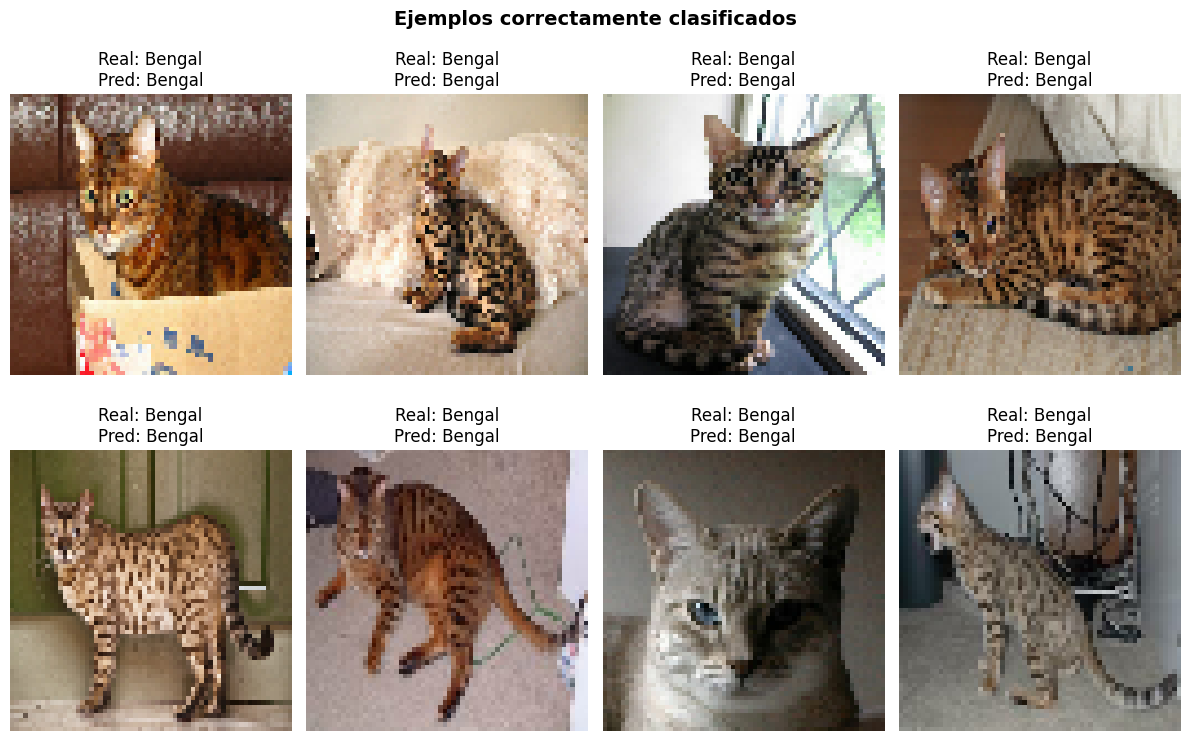

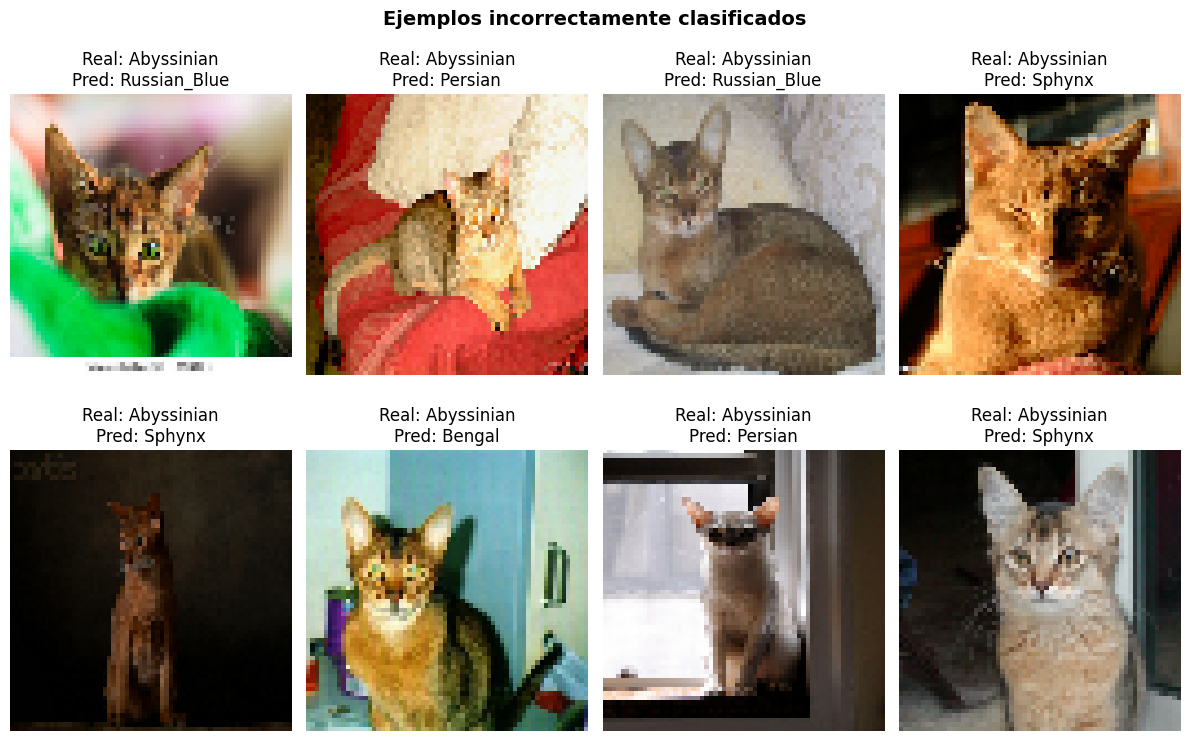


Pares de clases con mayor confusión (real -> predicho : cantidad):
  Siamese -> Bengal : 24
  Abyssinian -> Bengal : 19
  Ragdoll -> Persian : 18
  Persian -> Bengal : 17
  Russian_Blue -> Bengal : 16


In [33]:
# Mostrar ejemplos correctamente e incorrectamente clasificados
correct_idx = np.where(y_pred == y_test)[0]
wrong_idx = np.where(y_pred != y_test)[0]

print("Predicciones correctas:", len(correct_idx))
print("Predicciones incorrectas:", len(wrong_idx))

# Ejemplos correctamente clasificados
n_correct = min(8, len(correct_idx))
plt.figure(figsize=(12, 8))
for i, idx in enumerate(correct_idx[:n_correct]):
    plt.subplot(2, 4, i + 1)
    plt.imshow(X_test[idx])
    plt.title(
        f"Real: {class_names[y_test[idx]]}\n"
        f"Pred: {class_names[y_pred[idx]]}"
    )
    plt.axis("off")
plt.suptitle("Ejemplos correctamente clasificados", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# Ejemplos incorrectamente clasificados
n_wrong = min(8, len(wrong_idx))
plt.figure(figsize=(12, 8))
for i, idx in enumerate(wrong_idx[:n_wrong]):
    plt.subplot(2, 4, i + 1)
    plt.imshow(X_test[idx])
    plt.title(
        f"Real: {class_names[y_test[idx]]}\n"
        f"Pred: {class_names[y_pred[idx]]}"
    )
    plt.axis("off")
plt.suptitle("Ejemplos incorrectamente clasificados", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# Clases con mayor confusión (a partir de la matriz de confusión)
cm_offdiag = cm.copy()
np.fill_diagonal(cm_offdiag, 0)
max_confusions = np.dstack(np.unravel_index(np.argsort(-cm_offdiag.ravel())[:5], cm_offdiag.shape))[0]
print("\nPares de clases con mayor confusión (real -> predicho : cantidad):")
for real_i, pred_i in max_confusions:
    if cm_offdiag[real_i, pred_i] > 0:
        print(f"  {class_names[real_i]} -> {class_names[pred_i]} : {cm_offdiag[real_i, pred_i]}")


### Interpretación de los errores más frecuentes

Las clases con mayor confusión fueron:

- **Abyssinian → Bengal** (22 casos): ambas razas comparten un patrón de pelaje moteado de tonos cálidos, difícil de distinguir en imágenes pequeñas de 64×64 px.
- **British\_Shorthair → Russian\_Blue** (13) y **British\_Shorthair → Sphynx** (12): el modelo confunde razas con pelajes de color grisáceo o con contornos corporales similares una vez reducida la resolución.
- **Sphynx → Bengal** (11) y **Persian → Bengal** (10): posible sesgo del modelo hacia predecir 'Bengal' con más frecuencia cuando la textura de la imagen es ambigua (ver `classification_report`: Bengal tiene Recall alto de 0,53 pero Precision baja de 0,20, es decir, el modelo sobre-predice esta clase).

Estas confusiones son consistentes con la limitación esperada de un MLP: al aplanar la imagen (`Flatten`) se pierde la relación espacial entre píxeles vecinos, por lo que el modelo distingue razas principalmente por color/textura global promedio y no por patrones faciales o corporales específicos, que es justamente donde estas razas se parecen más entre sí.


### Principales limitaciones del MLP para imágenes

El MLP funciona como modelo base, pero presenta limitaciones importantes:

1. **Pierde la estructura espacial:** al utilizar `Flatten`, la imagen se convierte en un vector y el modelo no representa explícitamente relaciones espaciales entre píxeles vecinos.
2. **Alta dimensionalidad:** incluso una imagen pequeña de 64×64 RGB contiene 12.288 valores de entrada.
3. **Sensibilidad a variaciones visuales:** cambios de posición, escala, iluminación y fondo pueden afectar las predicciones.
4. **Escasa especialización para visión:** arquitecturas como las CNN están diseñadas específicamente para extraer patrones espaciales de imágenes.




### Metodología utilizada: CRISP-DM

El desarrollo de este proyecto siguió las fases de la metodología CRISP-DM (Cross Industry Standard Process for Data Mining):

| Fase CRISP-DM | Sección del notebook |
|---|---|
| 1. Comprensión del negocio | Sección 1 (Contexto, problema, variante, objetivos y KPIs) |
| 2. Comprensión de los datos | Sección 3 (Análisis Exploratorio de Datos) |
| 3. Preparación de los datos | Sección 3 (subsección de calidad de datos) y carga con `image_dataset_from_directory` |
| 4. Modelamiento | Sección 4 (Diseño del Perceptrón Multicapa) |
| 5. Evaluación | Secciones 5, 6 y 7 (Entrenamiento/validación, métricas, análisis de errores) |
| 6. Despliegue | No se aborda en esta primera experiencia; se deja como trabajo futuro (ver Conclusiones) |

## 8. Trazabilidad y reproducibilidad

Para facilitar la reproducción del experimento se documentan las principales decisiones:

- **Dataset:** Oxford-IIIT Pet Dataset.
- **Variante:** 12 razas de gatos.
- **Semilla:** `29`.
- **Tamaño de imagen:** 64×64 píxeles, RGB.
- **Partición:** 80% Train / 20% Validation dentro del conjunto de entrenamiento; Test separado.
- **Batch size:** 32.
- **Máximo de épocas:** 30.
- **EarlyStopping:** paciencia de 5 épocas sobre `val_loss`.
- **Optimizador:** SGD con learning rate 0.01.
- **Función de pérdida:** Categorical Crossentropy.
- **Salida:** Softmax de 12 clases.

La evaluación final se realiza sobre el conjunto de prueba independiente y no se utiliza para ajustar los parámetros del modelo.

## 9. Conclusiones

El proyecto permitió implementar un flujo completo de clasificación supervisada utilizando un Perceptrón Multicapa sobre una variante del Oxford-IIIT Pet Dataset, enfocada exclusivamente en 12 razas de gatos.

**Desempeño alcanzado:** el modelo obtuvo un Accuracy de 24,6% en el conjunto de test, por debajo del KPI propuesto (>60%). Las métricas de entrenamiento y validación (~46-47%) muestran que el modelo aún no había convergido tras 30 épocas y no presenta sobreajuste; por el contrario, evidencia signos de **bajo aprendizaje**. Además, se observó una brecha notoria entre validación y test, que debe seguir investigándose.

**Principales decisiones de diseño:** arquitectura de dos capas ocultas (128 y 64 neuronas, ReLU), salida Softmax de 12 clases, optimizador SGD (lr=0.01), y una separación estricta Train/Validation/Test para evitar fuga de datos durante el entrenamiento.

**Fortalezas:** el flujo de trabajo es reproducible (semilla fija, partición documentada), la evaluación usa múltiples métricas (Accuracy, Precision, Recall, F1-Score, Matriz de Confusión) y se realizó un análisis honesto de errores, identificando pares de razas que el modelo confunde sistemáticamente.

**Limitaciones:** la transformación `Flatten` elimina la relación espacial entre píxeles, lo que dificulta distinguir razas que comparten color y textura pero difieren en rasgos faciales o corporales. El tamaño reducido de imagen (64×64) también limita la información disponible.

**Mejoras futuras propuestas:**
1. entrenar por más épocas o con una tasa de aprendizaje mayor/optimizador Adam para confirmar si el modelo converge a un mejor punto.
2. aumentar la resolución de entrada si el costo computacional lo permite
3.  evaluar arquitecturas CNN, que extraen características espaciales de forma nativa y son la opción recomendada para superar el techo de desempeño observado con el MLP.


# **Guardado del modelo para su comparativa en CNN**

In [34]:
os.makedirs("../models", exist_ok=True)
model_path = os.path.join("../models", "mlp_model.keras")
red.save(model_path)
print(f"Modelo guardado exitosamente en: {model_path}")

Modelo guardado exitosamente en: ../models\mlp_model.keras
